<a href="https://colab.research.google.com/github/aurora-nat/Data_Dashboard_ClimateChange/blob/main/labs/lab5/semantic_segmentation_pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Semantic Segmentation in PyTorch

This notebook is about **semantic segmentation** using **Oxford-IIIT Pet** dataset.

By the end, you will:
- understand what semantic segmentation is
- load and inspect a segmentation dataset
- build a lightweight **U-Net**
- train it in **PyTorch**
- evaluate it with **IoU** and **Dice score**
- visualize predictions

Oxford-IIIT Pet has built-in **segmentation masks**
- it can be downloaded directly through `torchvision`

## Task formulation
The original masks include multiple labels. In this notebook, we convert them into a simpler task:


In [3]:
# If torchvision import fails in Colab because of a version mismatch,
# uncomment the next line and run this cell again.
# !pip -q install -U torch torchvision torchaudio

import os
import random
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import OxfordIIITPet
from torchvision.transforms import functional as TF
from torchvision.transforms.functional import InterpolationMode

print("torch:", torch.__version__)
import torchvision
print("torchvision:", torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

torch: 2.11.0+cu130
torchvision: 0.26.0+cu130
Using device: cuda


In [4]:
# Reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

## 1. How segmentation masks work in this dataset

The Oxford-IIIT Pet trimap masks use integer labels:
- **1** = pet
- **2** = background
- **3** = border / outline region

To make the labels convenient for `nn.CrossEntropyLoss()`, we remap them to:
- original **1 (pet)** -> class **0**
- original **2 (background)** -> class **1**
- original **3 (border)** -> class **2**

So every pixel belongs to exactly one of **3 semantic classes**.


In [5]:
class PetSegmentationDataset(torch.utils.data.Dataset):
    def __init__(self, root="./data", split="trainval", image_size=128, augment=False):
        self.dataset = OxfordIIITPet(
            root=root,
            split=split,
            target_types="segmentation",
            download=True
        )
        self.image_size = image_size
        self.augment = augment

        # ImageNet normalization is a good default for natural images
        self.mean = [0.485, 0.456, 0.406]
        self.std = [0.229, 0.224, 0.225]

        # Class names after remapping:
        # 0 = pet, 1 = background, 2 = border
        self.class_names = ["pet", "background", "border"]

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image, mask = self.dataset[idx]  # both are PIL Images

        # --- simple paired augmentation ---
        if self.augment and random.random() < 0.5:
            image = TF.hflip(image)
            mask = TF.hflip(mask)

        # Resize image and mask together
        image = TF.resize(image, [self.image_size, self.image_size], interpolation=InterpolationMode.BILINEAR)
        mask = TF.resize(mask, [self.image_size, self.image_size], interpolation=InterpolationMode.NEAREST)

        # Convert image to tensor and normalize
        image = TF.to_tensor(image)
        image = TF.normalize(image, mean=self.mean, std=self.std)

        # Convert mask to integer class IDs
        mask = torch.from_numpy(np.array(mask, dtype=np.int64)).long()

        # Oxford-IIIT Pet trimap original labels:
        # 1 = pet, 2 = background, 3 = border
        # Remap to 0, 1, 2 for CrossEntropyLoss
        mask = mask - 1  # shape: [H, W]

        return image, mask


In [6]:
# Build train/validation/test sets
full_trainval = PetSegmentationDataset(split="trainval", image_size=128, augment=True)
test_dataset = PetSegmentationDataset(split="test", image_size=128, augment=False)

# For speed in Colab, students can train on a subset.
# Increase max_train_samples for better results if you have more time.
max_train_samples = 2000
max_val_samples = 400

indices = list(range(len(full_trainval)))
random.shuffle(indices)

subset_size = min(max_train_samples + max_val_samples, len(indices))
indices = indices[:subset_size]

train_indices = indices[:min(max_train_samples, len(indices))]
val_indices = indices[min(max_train_samples, len(indices)):subset_size]
print(f"Train indices: {train_indices}")
print(f"Val indices:   {val_indices}")
train_dataset = torch.utils.data.Subset(full_trainval, train_indices)

# Validation should not use augmentation, so we make a second base dataset
full_trainval_no_aug = PetSegmentationDataset(split="trainval", image_size=128, augment=False)
val_dataset = torch.utils.data.Subset(full_trainval_no_aug, val_indices)

batch_size = 16

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train samples: {len(train_dataset)}")
print(f"Val samples:   {len(val_dataset)}")
print(f"Test samples:  {len(test_dataset)}")

100%|██████████| 792M/792M [00:30<00:00, 26.3MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.8MB/s]


Train indices: [2828, 1735, 599, 351, 1797, 1067, 1708, 3455, 3584, 1009, 2302, 2524, 1302, 667, 2806, 523, 2937, 3578, 3346, 1685, 2210, 2083, 3445, 2631, 2807, 1844, 2693, 2511, 934, 834, 3071, 2046, 3011, 2030, 2808, 668, 141, 321, 1749, 414, 2689, 985, 361, 3042, 1332, 1053, 1247, 756, 2224, 1878, 2319, 319, 3513, 2496, 1920, 3065, 2188, 2479, 1329, 530, 2886, 44, 3077, 3045, 718, 3548, 503, 2821, 2729, 773, 2147, 3657, 2273, 2280, 1267, 3180, 2630, 1411, 238, 3165, 206, 2887, 2353, 747, 3339, 1399, 3582, 1199, 3301, 2888, 1823, 2136, 1795, 904, 2380, 416, 20, 1507, 312, 3417, 595, 365, 638, 2160, 2486, 573, 114, 1700, 850, 3491, 1423, 2428, 1684, 3367, 165, 1915, 3504, 1652, 2973, 148, 3561, 3393, 387, 2100, 3376, 1830, 1828, 1681, 2475, 371, 2219, 0, 3060, 1907, 1972, 1120, 2529, 1611, 2846, 1895, 19, 639, 3125, 2960, 1875, 36, 1252, 1818, 2967, 2673, 1163, 797, 1727, 505, 1151, 832, 1206, 3122, 2918, 3553, 2501, 1690, 1548, 2327, 1502, 1256, 3085, 863, 1289, 3555, 3599, 145, 115

In [7]:
x = torch.arange(12)

A = x.view(3, 4)     # Valid: 3 × 4 = 12
B = x.view(2, 2, 3)  # Valid: 2 × 2 × 3 = 12
C = x.view(3, 1, 4)  # Valid: 3 × 1 × 4 = 12


print(f"A: {A} and shape: {A.shape}")
print(f"B: {B} and shape: {B.shape}")
print(f"C: {C} and shape: {C.shape}")
print(f"X: {x} and shape: {x.shape}")

A: tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]]) and shape: torch.Size([3, 4])
B: tensor([[[ 0,  1,  2],
         [ 3,  4,  5]],

        [[ 6,  7,  8],
         [ 9, 10, 11]]]) and shape: torch.Size([2, 2, 3])
C: tensor([[[ 0,  1,  2,  3]],

        [[ 4,  5,  6,  7]],

        [[ 8,  9, 10, 11]]]) and shape: torch.Size([3, 1, 4])
X: tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11]) and shape: torch.Size([12])


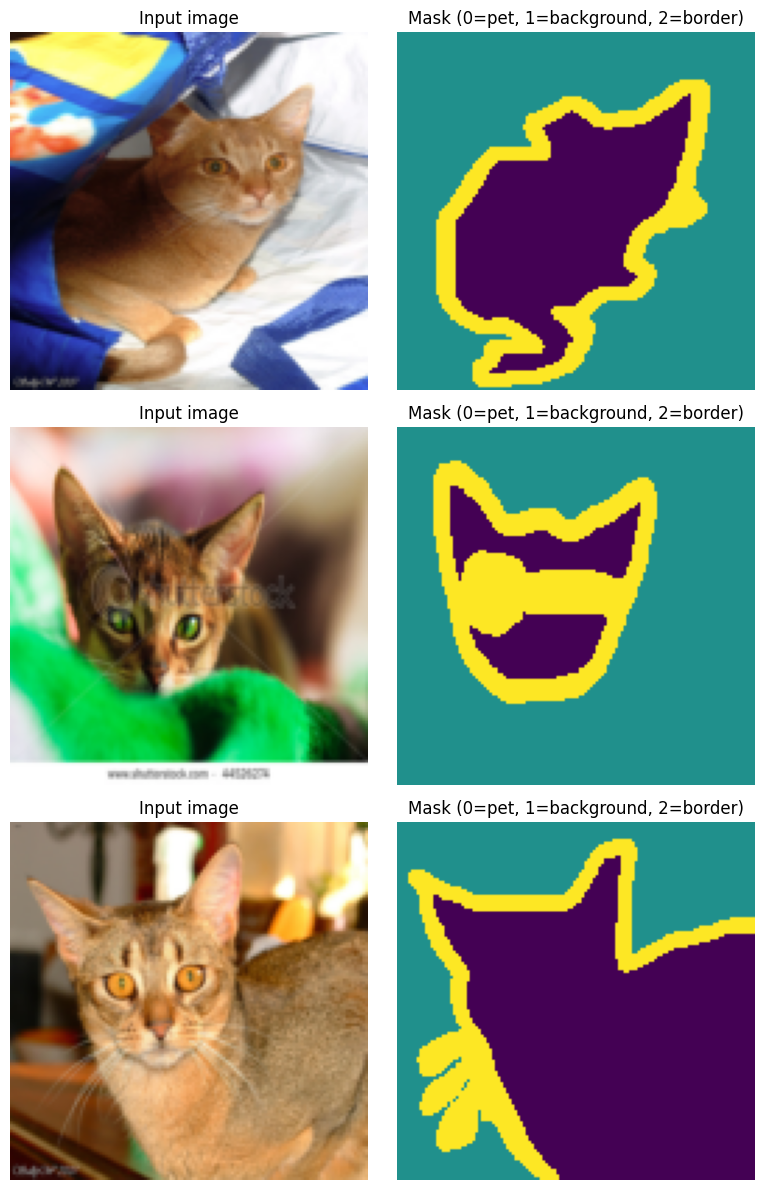

In [8]:
# Visualize a few image/mask pairs
def denormalize(img, mean, std):
    mean = torch.tensor(mean).view(3, 1, 1)
    std = torch.tensor(std).view(3, 1, 1)
    return img * std + mean

base_ds = full_trainval_no_aug
class_cmap = "viridis"

fig, axes = plt.subplots(3, 2, figsize=(8, 12))
for row in range(3):
    img, mask = base_ds[row]
    img = denormalize(img, base_ds.mean, base_ds.std).clamp(0, 1)

    axes[row, 0].imshow(img.permute(1, 2, 0))
    axes[row, 0].set_title("Input image")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(mask, cmap=class_cmap, vmin=0, vmax=2)
    axes[row, 1].set_title("Mask (0=pet, 1=background, 2=border)")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()


## 2. Build a lightweight U-Net

U-Net is one of the most common architectures for segmentation.

Its key idea is:

- **encoder**: compress spatial information into richer features
- **decoder**: recover spatial detail
- **skip connections**: pass fine-grained information from encoder to decoder

For **multi-class segmentation**, the final layer outputs **3 channels**:
one per class (`pet`, `background`, `border`).


In [9]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNetSmall(nn.Module):
    def __init__(self, in_channels=3, out_channels=3, features=(32, 64, 128, 256)):
        super().__init__()
        self.downs = nn.ModuleList()
        self.ups = nn.ModuleList()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Down path
        ch = in_channels
        for feature in features:
            self.downs.append(DoubleConv(ch, feature))
            ch = feature

        # Bottleneck
        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)

        # Up path
        rev_features = features[::-1]
        up_in = features[-1] * 2
        for feature in rev_features:
            self.ups.append(nn.ConvTranspose2d(up_in, feature, kernel_size=2, stride=2))
            self.ups.append(DoubleConv(feature * 2, feature))
            up_in = feature

        self.final_conv = nn.Conv2d(features[0], out_channels, kernel_size=1)

    def forward(self, x):
        skip_connections = []

        for down in self.downs:
            x = down(x)
            skip_connections.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)
        skip_connections = skip_connections[::-1]

        for idx in range(0, len(self.ups), 2):
            x = self.ups[idx](x)
            skip = skip_connections[idx // 2]

            if x.shape != skip.shape:
                x = TF.resize(x, size=list(skip.shape[-2:]))

            x = torch.cat((skip, x), dim=1)
            x = self.ups[idx + 1](x)

        return self.final_conv(x)


model = UNetSmall(out_channels=3).to(device)
model


UNetSmall(
  (downs): ModuleList(
    (0): DoubleConv(
      (block): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
      )
    )
    (1): DoubleConv(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace

## 3. Loss, metrics, and helpers

We use:
- **CrossEntropyLoss** for multi-class segmentation
- **mean IoU** across classes
- **mean Dice score** across classes

For each pixel, the model predicts logits for the 3 classes:
`pet`, `background`, and `border`.

We convert logits to class predictions using `argmax`.


### IoU and Dice

In semantic segmentation, we compare the predicted mask with the ground-truth mask using overlap metrics.

**IoU (Intersection over Union)** measures the fraction of overlap between prediction and truth out of their combined area:

$$
\text{IoU} = \frac{|P \cap T|}{|P \cup T|}
$$

**Dice** measures overlap too, but gives more weight to the shared region:

$$
\text{Dice} = \frac{2|P \cap T|}{|P| + |T|}
$$

Where:
- \(P\) = predicted pixels for a class
- \(T\) = true pixels for a class

In [10]:
NUM_CLASSES = 3

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


def compute_batch_metrics(logits, masks, num_classes=NUM_CLASSES, eps=1e-7):
    preds = torch.argmax(logits, dim=1)  # [B, H, W]

    ious = []
    dices = []

    for class_idx in range(num_classes):
        pred_c = (preds == class_idx)
        mask_c = (masks == class_idx)

        intersection = (pred_c & mask_c).sum(dim=(1, 2)).float()
        union = (pred_c | mask_c).sum(dim=(1, 2)).float()
        pred_area = pred_c.sum(dim=(1, 2)).float()
        mask_area = mask_c.sum(dim=(1, 2)).float()

        iou_c = (intersection + eps) / (union + eps)
        dice_c = (2 * intersection + eps) / (pred_area + mask_area + eps)

        ious.append(iou_c)
        dices.append(dice_c)

    # shape after stack: [num_classes, batch_size]
    mean_iou = torch.stack(ious, dim=0).mean().item()
    mean_dice = torch.stack(dices, dim=0).mean().item()
    return mean_iou, mean_dice


def train_one_epoch(model, loader, optimizer, loss_fn, device):
    model.train()
    running_loss = 0.0
    running_iou = 0.0
    running_dice = 0.0

    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
            logits = model(images)          # [B, 3, H, W]
            loss = loss_fn(logits, masks)   # masks: [B, H, W]

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        iou, dice = compute_batch_metrics(logits.detach(), masks)

        running_loss += loss.item()
        running_iou += iou
        running_dice += dice

    n = len(loader)
    return running_loss / n, running_iou / n, running_dice / n


@torch.no_grad()
def evaluate(model, loader, loss_fn, device):
    model.eval()
    running_loss = 0.0
    running_iou = 0.0
    running_dice = 0.0

    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        logits = model(images)
        loss = loss_fn(logits, masks)
        iou, dice = compute_batch_metrics(logits, masks)

        running_loss += loss.item()
        running_iou += iou
        running_dice += dice

    n = len(loader)
    return running_loss / n, running_iou / n, running_dice / n


/tmp/ipykernel_586/1220001419.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


## 4. Train the model

The default settings are chosen so the notebook finishes in a reasonable time in Colab.

Tips:
- Increase `epochs` for better quality.
- Increase `max_train_samples` earlier in the notebook if you want to train on more data.
- Switch to a GPU in Colab for much faster training.

In [11]:
epochs = 10
history = {
    "train_loss": [],
    "train_iou": [],
    "train_dice": [],
    "val_loss": [],
    "val_iou": [],
    "val_dice": [],
}

best_val_iou = -1.0
best_model_path = "best_unet_pet_segmentation.pth"

for epoch in range(1, epochs + 1):
    start = time.time()

    train_loss, train_iou, train_dice = train_one_epoch(model, train_loader, optimizer, loss_fn, device)
    val_loss, val_iou, val_dice = evaluate(model, val_loader, loss_fn, device)

    history["train_loss"].append(train_loss)
    history["train_iou"].append(train_iou)
    history["train_dice"].append(train_dice)
    history["val_loss"].append(val_loss)
    history["val_iou"].append(val_iou)
    history["val_dice"].append(val_dice)

    if val_iou > best_val_iou:
        best_val_iou = val_iou
        torch.save(model.state_dict(), best_model_path)

    elapsed = time.time() - start
    print(
        f"Epoch {epoch:02d}/{epochs} | "
        f"train_loss={train_loss:.4f}, train_iou={train_iou:.4f}, train_dice={train_dice:.4f} | "
        f"val_loss={val_loss:.4f}, val_iou={val_iou:.4f}, val_dice={val_dice:.4f} | "
        f"time={elapsed:.1f}s"
    )

print(f"\nBest model saved to: {best_model_path}")

/tmp/ipykernel_586/1220001419.py:47: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):


Epoch 01/10 | train_loss=0.6854, train_iou=0.4402, train_dice=0.5601 | val_loss=0.5695, val_iou=0.5000, val_dice=0.6221 | time=15.0s
Epoch 02/10 | train_loss=0.5654, train_iou=0.5037, train_dice=0.6226 | val_loss=0.5184, val_iou=0.5242, val_dice=0.6414 | time=12.7s
Epoch 03/10 | train_loss=0.5027, train_iou=0.5476, train_dice=0.6655 | val_loss=0.4815, val_iou=0.5568, val_dice=0.6731 | time=12.7s
Epoch 04/10 | train_loss=0.4577, train_iou=0.5818, train_dice=0.6988 | val_loss=0.4760, val_iou=0.5893, val_dice=0.7084 | time=12.5s
Epoch 05/10 | train_loss=0.4197, train_iou=0.6090, train_dice=0.7237 | val_loss=0.3951, val_iou=0.6252, val_dice=0.7385 | time=12.6s
Epoch 06/10 | train_loss=0.3879, train_iou=0.6300, train_dice=0.7420 | val_loss=0.3861, val_iou=0.6192, val_dice=0.7306 | time=12.6s
Epoch 07/10 | train_loss=0.3792, train_iou=0.6358, train_dice=0.7472 | val_loss=0.3870, val_iou=0.6325, val_dice=0.7469 | time=12.5s
Epoch 08/10 | train_loss=0.3576, train_iou=0.6506, train_dice=0.7598 

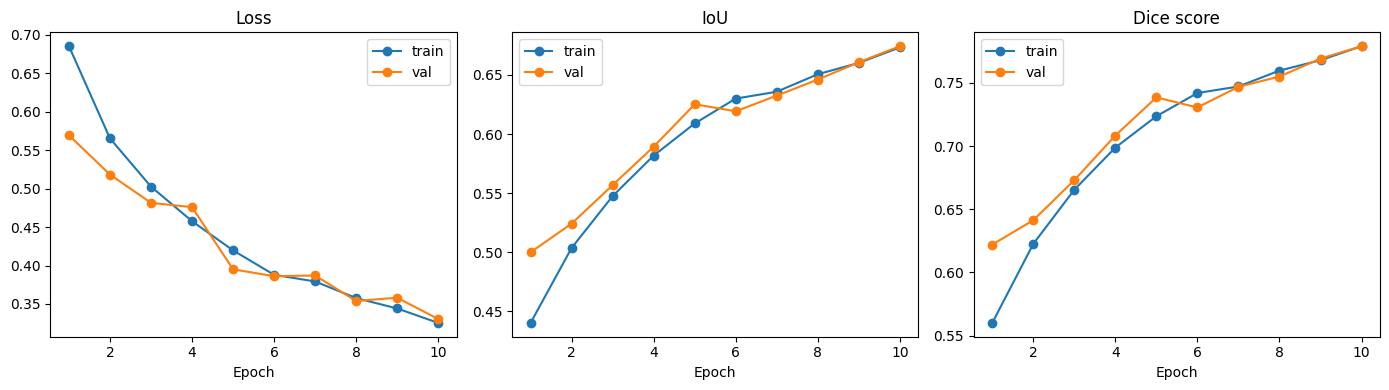

In [12]:
# Plot learning curves
epochs_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.plot(epochs_range, history["train_loss"], marker="o", label="train")
plt.plot(epochs_range, history["val_loss"], marker="o", label="val")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(epochs_range, history["train_iou"], marker="o", label="train")
plt.plot(epochs_range, history["val_iou"], marker="o", label="val")
plt.title("IoU")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(epochs_range, history["train_dice"], marker="o", label="train")
plt.plot(epochs_range, history["val_dice"], marker="o", label="val")
plt.title("Dice score")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

## 5. Test set evaluation
We now reload the best checkpoint and evaluate it on the held-out test set.

In [13]:
best_model = UNetSmall(out_channels=3).to(device)
best_model.load_state_dict(torch.load(best_model_path, map_location=device))

test_loss, test_iou, test_dice = evaluate(best_model, test_loader, loss_fn, device)

print(f"Test loss      : {test_loss:.4f}")
print(f"Test mean IoU  : {test_iou:.4f}")
print(f"Test mean Dice : {test_dice:.4f}")


Test loss      : 0.3274
Test mean IoU  : 0.6813
Test mean Dice : 0.7857


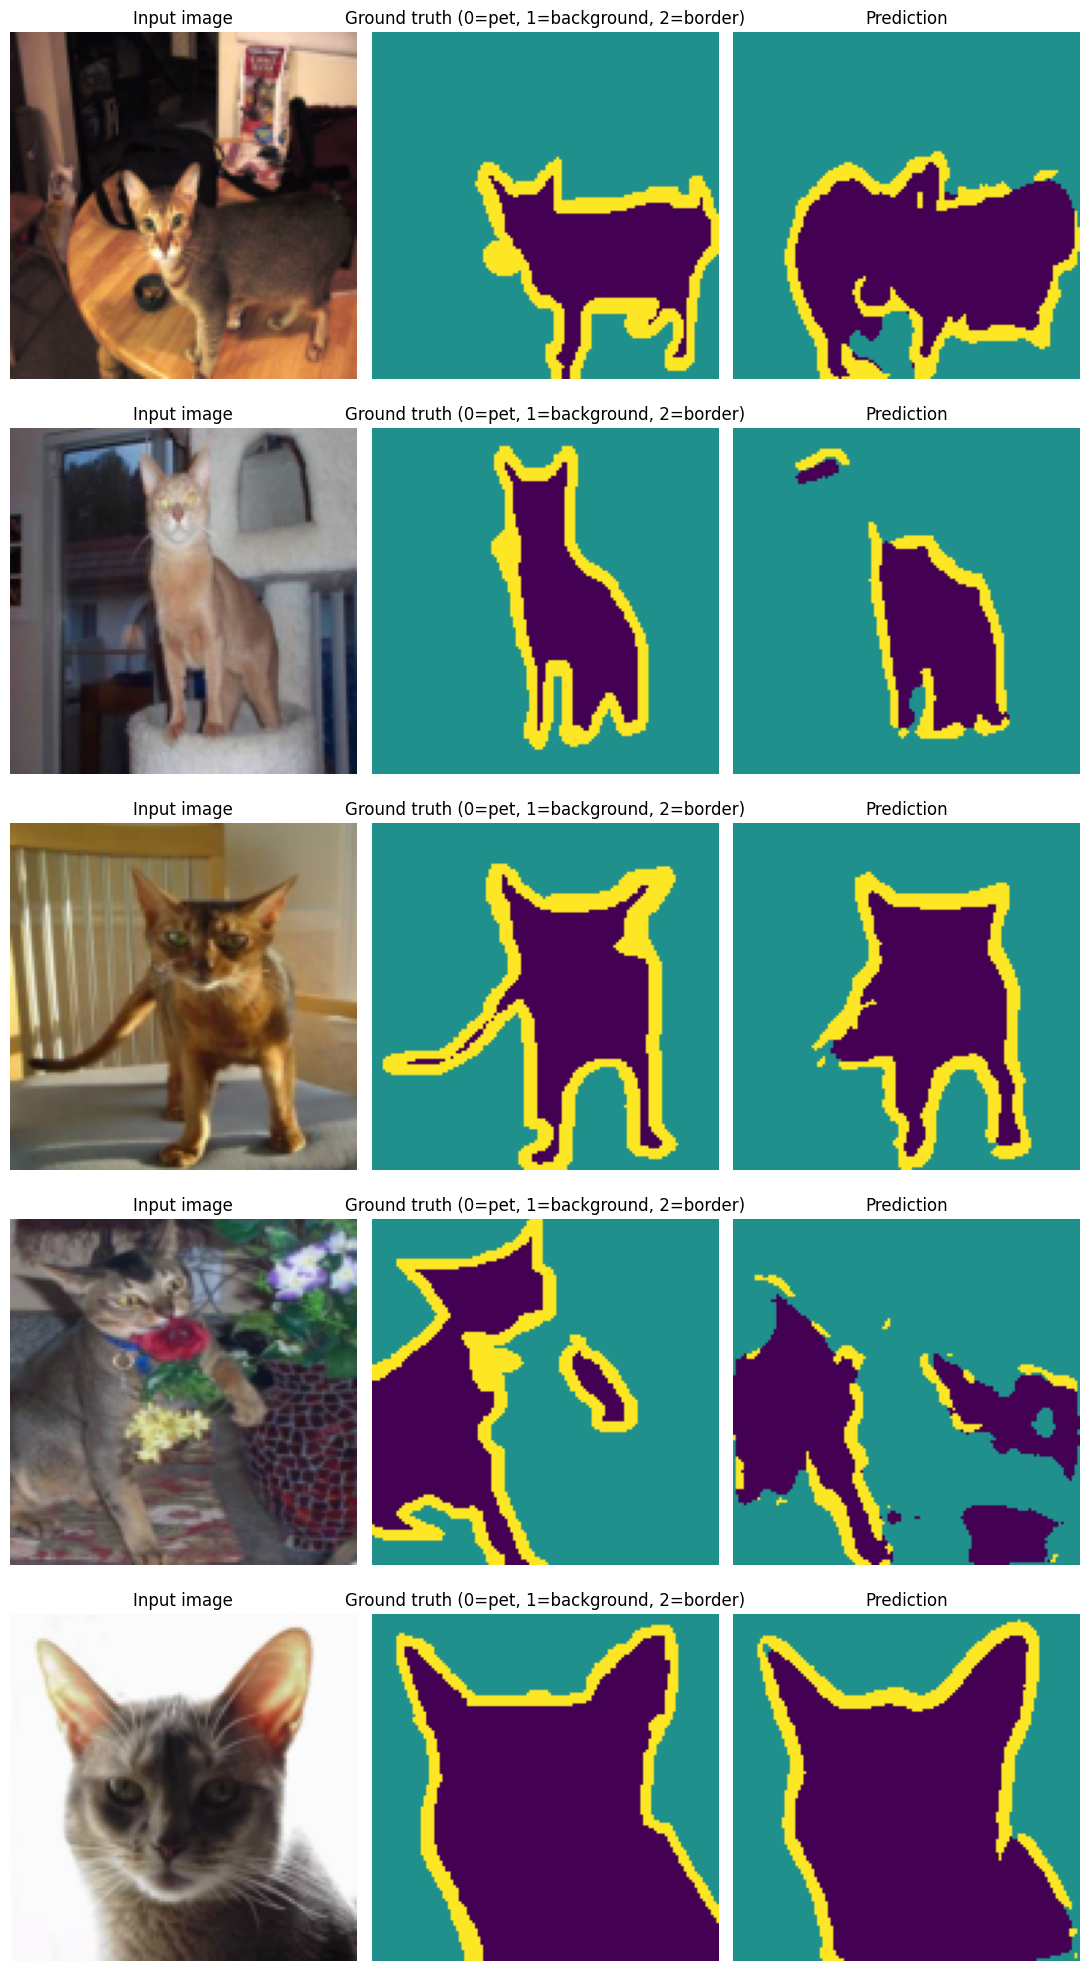

In [14]:
@torch.no_grad()
def show_predictions(model, dataset, device, num_samples=5):
    model.eval()
    mean = torch.tensor(dataset.mean).view(3, 1, 1)
    std = torch.tensor(dataset.std).view(3, 1, 1)

    fig, axes = plt.subplots(num_samples, 3, figsize=(11, 4 * num_samples))
    if num_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(num_samples):
        image, mask = dataset[i]
        logits = model(image.unsqueeze(0).to(device))
        pred = torch.argmax(logits, dim=1).squeeze(0).cpu()

        image_vis = (image.cpu() * std + mean).clamp(0, 1)

        axes[i, 0].imshow(image_vis.permute(1, 2, 0))
        axes[i, 0].set_title("Input image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(mask, cmap="viridis", vmin=0, vmax=2)
        axes[i, 1].set_title("Ground truth (0=pet, 1=background, 2=border)")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(pred, cmap="viridis", vmin=0, vmax=2)
        axes[i, 2].set_title("Prediction")
        axes[i, 2].axis("off")

    plt.tight_layout()
    plt.show()

show_predictions(best_model, test_dataset, device, num_samples=5)


## 6. What you should learn from this notebook

1. The model predicts a class for **every pixel**, not one label per image.

2. For `CrossEntropyLoss`, targets should be shaped `[H, W]` (or `[B, H, W]` in batches) with integer class labels.

3. **Mask resizing must use nearest-neighbor interpolation**  
   Bilinear interpolation would invent invalid class values between labels.

4. **The output channel count matches the number of classes**  
   Here the model outputs **3 channels**: pet, background, border.

5. **Argmax turns logits into final class predictions**  
   During inference, the predicted class at each pixel is the channel with the highest logit.

### Practical skills
- loading a real segmentation dataset
- building a U-Net in PyTorch
- training with `CrossEntropyLoss`
- evaluating with mean IoU and mean Dice
- visualizing multiclass predictions


## 7. Extension ideas

You can try:
- increasing image resolution from **128** to **160** or **192**
- training for more epochs
- adding stronger data augmentation
- computing **per-class IoU** for pet, background, and border separately
- replacing the custom U-Net with a pretrained segmentation backbone later

A good next exercise is to compare:
- **overall mean IoU**
- **per-class IoU**
- qualitative prediction quality on thin border regions
